# 01 · Arquitectura Python y FastAPI

Sigue una solicitud HTTP, distingue los componentes de la pila Python y ubica la inicialización de los recursos compartidos.

[Índice del backend](README.md) · [Anterior · Instalar, configurar y arrancar](00_ejecucion_y_entorno.ipynb) · [Siguiente · PostgreSQL y persistencia](02_postgresql_y_persistencia.ipynb)

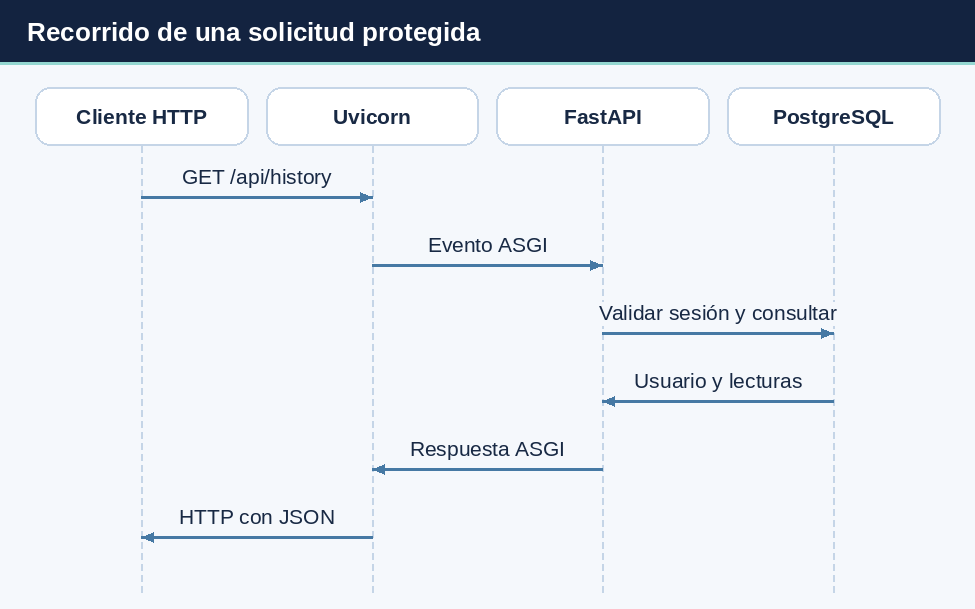

## HTTP, ASGI y el framework

**HTTP** es el protocolo de intercambio con el cliente. Una solicitud identifica un método, una ruta, cabeceras y un cuerpo opcional. La respuesta contiene un estado, cabeceras y un cuerpo. El historial utiliza `GET`. El inicio de sesión utiliza `POST` porque envía credenciales y establece una cookie.

**ASGI** separa el servidor Python de la aplicación web. Define un ámbito o `scope` de conexión y dos funciones asíncronas para recibir y enviar eventos. La aplicación puede producir una respuesta completa o entregar su contenido por fragmentos. Así se puede sostener una conexión para eventos del panel.

| Tecnología | Responsabilidad |
| --- | --- |
| Uvicorn | Escucha en el puerto HTTP, interpreta las solicitudes entrantes y las entrega a la aplicación ASGI. |
| FastAPI | Registra rutas, aplica dependencias, valida parámetros y genera el contrato OpenAPI a partir de las anotaciones. |
| Starlette | Ofrece soporte ASGI usado por FastAPI, incluidas peticiones, respuestas en streaming, archivos estáticos y ejecución de trabajo bloqueante fuera del bucle. |
| Pydantic | Valida el modelo de credenciales y participa en la validación de argumentos de las rutas. |
| Psycopg y psycopg_pool | Gestionan acceso y conexiones reutilizables a PostgreSQL. |
| PyJWT y pwdlib | Firman y validan tokens y verifican hashes de contraseñas. |
| Paho MQTT | Mantiene el cliente MQTT y reparte mensajes a callbacks Python. |

El argumento `backend.app:app` de Uvicorn identifica el módulo Python a la izquierda y el objeto a la derecha. El módulo es `backend/app.py` y el objeto es la instancia creada con `FastAPI(...)`.

## Mapa del código

| Archivo | Qué buscar |
| --- | --- |
| `backend/app.py` | Ciclo de vida, routers, SSE, filtros, caché y montaje estático. |
| `backend/config.py` | Lectura de variables y función `database_url()`. |
| `backend/db.py` | Inicialización, pool, escritura de lecturas, consultas y exportación. |
| `backend/schema.sql` | Tablas, índices y transición desde nombres históricos. |
| `backend/auth.py` | Validación de credenciales, JWT en cookie y dependencia de sesión. |
| `backend/users.py` | Creación interactiva de cuentas. |
| `backend/mqtt_ingest.py` | Recepción y validación de telemetría, cola y confirmación del reenvío. |
| `backend/scripts/mqtt_bridge/` | Conversor reutilizado por el backend y el ejecutable independiente. |

`app.py` monta la interfaz compilada con `StaticFiles` si existe `frontend/dist` al importar la aplicación. Primero registra el router `/api`, luego el montaje de `/`. Esto permite entregar API y recursos web desde el mismo origen.

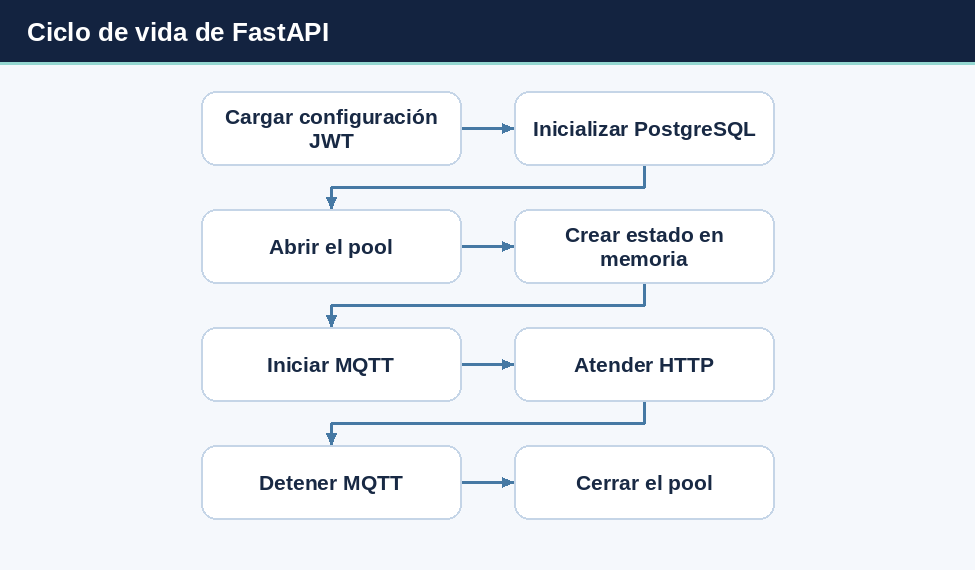

## Inicio, estado y apagado

`lifespan` es un administrador de contexto asíncrono. El código anterior a `yield` prepara recursos. Durante `yield` la aplicación acepta solicitudes. Al detenerse, `finally` desconecta MQTT, espera a que se detenga su trabajador y cierra el pool PostgreSQL.

El pool y `LiveState` en `app.state` se comparten dentro de un **proceso**. Permiten atender solicitudes concurrentes sin volver a crear el pool en cada una. Dos procesos separados tendrían su propio estado en memoria y sus propios clientes MQTT. Con el mismo identificador MQTT podrían desplazarse entre sí. El comando de desarrollo arranca un solo proceso.

`LiveState` conserva si el broker confirmó la suscripción, los últimos estados de los dispositivos y un `asyncio.Event` de cambio. Un reinicio pierde esa parte en memoria. PostgreSQL conserva las lecturas y permite reconstruir la primera instantánea posterior al arranque.

## Tipos, dependencias y concurrencia en Python

Estas declaraciones son parte del contrato de la ruta.

```python
DeviceId = Annotated[str, Query(min_length=1, max_length=128)]
```

`str` es el tipo de dato. `Annotated` adjunta metadatos. `Query` indica que el valor se lee desde los parámetros de URL y aplica límites de longitud. `Literal["day", "week", "month"]` enumera los periodos de la serie. Los valores incompatibles se rechazan con `422`.

`Depends(...)` declara una función que FastAPI ejecuta antes del controlador. Las rutas de lecturas usan `session_required` para validar la sesión. Historial y CSV comparten `history_filters` y por ello usan las mismas reglas de fechas.

Un controlador de ruta normal con `def` se ejecuta en el conjunto de hilos del servidor. Las consultas SQL usan Psycopg sincrónico. Los controladores `async def` emplean el bucle de eventos y pueden pausar su trabajo con `await`. SSE usa `run_in_threadpool` para trasladar su consulta bloqueante a un hilo, de modo que el bucle pueda atender otras conexiones.

## Ejercicio de lectura

1. En `backend/app.py`, sigue las funciones registradas con `@api.get` y `@readings_api.get` hasta sus rutas finales.
2. Localiza la construcción del pool y compara un fallo PostgreSQL al iniciar con una desconexión del broker cuando la API ya está sirviendo HTTP.
3. En `http://127.0.0.1:8000/openapi.json`, localiza `paths` y el esquema `Credentials`. Relaciona los límites de longitud en Python con la descripción consumida por clientes.
4. Compara la respuesta de historial con SSE. La primera entrega un objeto JSON completo. La segunda emite varias instantáneas durante una sola solicitud.

[Índice del backend](README.md) · [Anterior · Instalar, configurar y arrancar](00_ejecucion_y_entorno.ipynb) · [Siguiente · PostgreSQL y persistencia](02_postgresql_y_persistencia.ipynb)